# V0.1 data contracts

This executed example uses only synthetic data. It creates a session with two swings, writes validated JSON and Parquet records, reads them back, plots a wrist trajectory, and adds a manual event correction without changing the original model annotation.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt

from open_swing_analysis.contracts import ObservationLayer
from open_swing_analysis.storage import LocalDataStore
from open_swing_analysis.synthetic import create_synthetic_dataset

dataset = create_synthetic_dataset()
print(f"Session: {dataset.session.session_id}")
print(f"Camera/handedness: {dataset.session.camera_view.value} / {dataset.session.golfer_handedness.value}")
print("Swings:", [(s.swing_id, s.club_type) for s in dataset.swings])

Session: session-synthetic-001
Camera/handedness: face_on / right
Swings: [('swing-synthetic-001', '7-iron'), ('swing-synthetic-002', 'driver')]


## Write metadata and observation tables

The fixture deliberately includes irregular timestamps, one frame with no pose rows, low-confidence landmarks, an invalid-status row with null coordinates, and a second swing in the same session. The manual impact correction is held back until the final section.

In [2]:
temporary_directory = tempfile.TemporaryDirectory(prefix="open-swing-contracts-")
store = LocalDataStore(Path(temporary_directory.name))
session_id = dataset.session.session_id

store.write_session(dataset.session)
store.write_video_asset(session_id, dataset.asset)
for swing in dataset.swings:
    store.write_swing(swing)
    store.write_frames(session_id, swing.swing_id, dataset.frames[swing.swing_id])
    store.write_pose_observations(
        session_id, swing.swing_id, dataset.pose_observations[swing.swing_id]
    )

manual_correction = next(
    event for event in dataset.event_annotations if event.corrects_annotation_id is not None
)
for event in dataset.event_annotations:
    if event.annotation_id != manual_correction.annotation_id:
        store.write_event_annotation(session_id, event)
for outcome in dataset.shot_outcomes:
    store.write_shot_outcome(session_id, outcome)

print("Stored files:")
for relative_path in store.tree():
    print(" -", relative_path)

Stored files:
 - sessions/session-synthetic-001/assets/asset-synthetic-001.json
 - sessions/session-synthetic-001/session.json
 - sessions/session-synthetic-001/swings/swing-synthetic-001/annotations/events/event-address-manual-001.json
 - sessions/session-synthetic-001/swings/swing-synthetic-001/annotations/events/event-backswing-start-manual-001.json
 - sessions/session-synthetic-001/swings/swing-synthetic-001/annotations/events/event-downswing-manual-001.json
 - sessions/session-synthetic-001/swings/swing-synthetic-001/annotations/events/event-finish-manual-001.json
 - sessions/session-synthetic-001/swings/swing-synthetic-001/annotations/events/event-impact-model-001.json
 - sessions/session-synthetic-001/swings/swing-synthetic-001/annotations/events/event-release-manual-001.json
 - sessions/session-synthetic-001/swings/swing-synthetic-001/annotations/events/event-takeaway-manual-001.json
 - sessions/session-synthetic-001/swings/swing-synthetic-001/annotations/events/event-top-manua

## Read and validate

Reads check contract versions, Arrow field types, Pydantic constraints, and frame/timestamp references. Pose detection is not required for every frame.

In [3]:
swing_id = dataset.swings[0].swing_id
frames = store.read_frames(session_id, swing_id)
raw_pose = store.read_pose_observations(
    session_id, swing_id, ObservationLayer.RAW, "raw-pose-run-001"
)
frame_indexes = {frame.frame_index for frame in frames}
pose_frame_indexes = {row.frame_index for row in raw_pose}

print(f"Validated {len(frames)} frames and {len(raw_pose)} pose rows")
print("Original timestamps:", [frame.timestamp_s for frame in frames])
print("Frames with no pose rows:", sorted(frame_indexes - pose_frame_indexes))
print("Null invalid rows:", [
    (row.landmark_name, row.x, row.y, row.confidence)
    for row in raw_pose if row.observation_status.value == "invalid"
])

Validated 6 frames and 11 pose rows
Original timestamps: [0.0, 0.033, 0.071, 0.102, 0.151, 0.184]
Frames with no pose rows: [2]
Null invalid rows: [('synthetic_invalid_landmark', None, None, None)]


## Display a landmark trajectory

The gap is kept as missing rather than filled. Image `y` increases downward, so the plot reverses that axis for a natural visual trajectory.

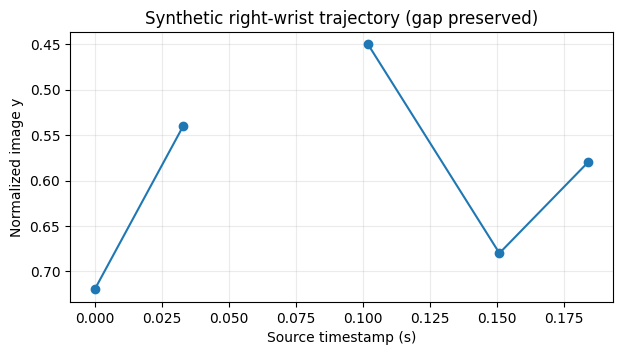

In [4]:
right_wrist_by_frame = {
    row.frame_index: row
    for row in raw_pose
    if row.landmark_name == "right_wrist"
}
trajectory_y = [
    right_wrist_by_frame[frame.frame_index].y
    if frame.frame_index in right_wrist_by_frame else None
    for frame in frames
]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([frame.timestamp_s for frame in frames], trajectory_y, marker="o")
ax.invert_yaxis()
ax.set(xlabel="Source timestamp (s)", ylabel="Normalized image y", title="Synthetic right-wrist trajectory (gap preserved)")
ax.grid(alpha=0.25)
plt.show()

## Add a non-destructive manual correction

The correction is a new event record linked by `corrects_annotation_id`. The model estimate remains byte-for-byte represented by the same validated object.

In [5]:
original_before = store.read_event_annotation(
    session_id, swing_id, manual_correction.corrects_annotation_id
)
store.write_event_annotation(session_id, manual_correction)
original_after = store.read_event_annotation(
    session_id, swing_id, manual_correction.corrects_annotation_id
)
stored_correction = store.read_event_annotation(
    session_id, swing_id, manual_correction.annotation_id
)

print("Original unchanged:", original_before == original_after)
print("Model event frame/time:", original_after.frame_index, original_after.timestamp_s)
print("Manual correction frame/time:", stored_correction.frame_index, stored_correction.timestamp_s)
print("Correction points to:", stored_correction.corrects_annotation_id)
print("Event records now stored:", len(store.read_event_annotations(session_id, swing_id)))

Original unchanged: True
Model event frame/time: 4 0.151
Manual correction frame/time: 3 0.102
Correction points to: event-impact-model-001
Event records now stored: 9


In [6]:
print("EXECUTED_OK")

EXECUTED_OK
